# PulmoAI — ViT (Vision Transformer) Chest X-Ray Multi-Label Classification

**Framework:** PyTorch + HuggingFace Transformers  
**Model:** `google/vit-base-patch16-224`  
**Amaç:** DenseNet121 sonuçlarıyla adil karşılaştırma — aynı split, aynı metrikler

> Runtime → Donanım Hızlandırıcı → **A100 GPU** seçili olsun.

## 1. Kurulum ve Drive Bağlama

In [2]:
# Gerekli kütüphaneler
!pip install -q transformers timm scikit-learn

from google.colab import drive
drive.mount('/content/drive')

import torch
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "YOK")
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

Mounted at /content/drive
PyTorch: 2.11.0+cu128
GPU: NVIDIA A100-SXM4-40GB
Device: cuda


## 2. CSV ve ZIP Hazırlığı

In [3]:
import zipfile, io, os
import pandas as pd
import numpy as np

ZIP_PATH = "/content/drive/MyDrive/Kaggle_Datasets/nih_chest_xrays/data.zip"

# CSV yükle
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    csv_name = next(n for n in zf.namelist() if 'Data_Entry' in n and n.endswith('.csv'))
    csv_bytes = zf.read(csv_name)

df = pd.read_csv(io.BytesIO(csv_bytes))
print("Toplam kayit:", len(df))

# ZIP içi PNG yollarını eşleştir
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    all_names = zf.namelist()

filename_to_zippath = {
    n.split('/')[-1]: n
    for n in all_names if n.lower().endswith('.png')
}
df['zip_path'] = df['Image Index'].map(filename_to_zippath)
df = df.dropna(subset=['zip_path']).reset_index(drop=True)
print("Eslesen kayit:", len(df))

Toplam kayit: 112120
Eslesen kayit: 112120


## 3. Multi-Hot Etiket Oluşturma

In [4]:
# DenseNet notebook ile AYNI etiketler — karşılaştırma için zorunlu
DISEASE_LABELS = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration", "Mass",
    "Nodule", "Pneumonia", "Pneumothorax", "Consolidation", "Edema",
    "Emphysema", "Fibrosis", "Pleural_Thickening", "Hernia"
]

def encode_labels(s):
    parts = s.split('|')
    return [1.0 if d in parts else 0.0 for d in DISEASE_LABELS]

label_matrix = np.stack(df['Finding Labels'].apply(encode_labels).values)
for i, d in enumerate(DISEASE_LABELS):
    df[d] = label_matrix[:, i]

print("Sinif basina pozitif ornek:")
print(df[DISEASE_LABELS].sum().sort_values(ascending=False))

Sinif basina pozitif ornek:
Infiltration          19894.0
Effusion              13317.0
Atelectasis           11559.0
Nodule                 6331.0
Mass                   5782.0
Pneumothorax           5302.0
Consolidation          4667.0
Pleural_Thickening     3385.0
Cardiomegaly           2776.0
Emphysema              2516.0
Edema                  2303.0
Fibrosis               1686.0
Pneumonia              1431.0
Hernia                  227.0
dtype: float64


## 4. Train / Val / Test Split — DenseNet ile AYNI

In [5]:
from sklearn.model_selection import train_test_split

# DenseNet notebook ile TAM AYNI parametreler
SUBSET_SIZE = 50000

unique_patients = df['Patient ID'].unique()
train_p, test_p = train_test_split(unique_patients, test_size=0.2, random_state=42)
train_p, val_p  = train_test_split(train_p,         test_size=0.1, random_state=42)

train_df = df[df['Patient ID'].isin(train_p)].reset_index(drop=True)
val_df   = df[df['Patient ID'].isin(val_p)].reset_index(drop=True)
test_df  = df[df['Patient ID'].isin(test_p)].reset_index(drop=True)

n_train = int(SUBSET_SIZE * 0.72)
n_val   = int(SUBSET_SIZE * 0.08)
n_test  = int(SUBSET_SIZE * 0.20)
train_df = train_df.sample(n=min(n_train, len(train_df)), random_state=42).reset_index(drop=True)
val_df   = val_df.sample(n=min(n_val,   len(val_df)),   random_state=42).reset_index(drop=True)
test_df  = test_df.sample(n=min(n_test,  len(test_df)),  random_state=42).reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 36000 | Val: 4000 | Test: 10000


## 5. Görüntüleri Extract Et

In [6]:
from tqdm.auto import tqdm

EXTRACT_DIR = "/content/nih_images"
os.makedirs(EXTRACT_DIR, exist_ok=True)

all_needed = set(pd.concat([train_df, val_df, test_df])['zip_path'].tolist())
already    = {f for f in os.listdir(EXTRACT_DIR)}
to_do      = [p for p in all_needed if os.path.basename(p) not in already]
print(f"Gerekli goruntu: {len(all_needed)}")
print(f"Zaten mevcut: {len(already)} | Extract edilecek: {len(to_do)}")

if to_do:
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        for zip_inner in tqdm(to_do, desc="Extracting"):
            target = os.path.join(EXTRACT_DIR, os.path.basename(zip_inner))
            with open(target, 'wb') as f:
                f.write(zf.read(zip_inner))

print("Extract tamam!")

# Local path ekle
def add_local_path(dataframe):
    dataframe = dataframe.copy()
    dataframe['local_path'] = dataframe['zip_path'].apply(
        lambda p: os.path.join(EXTRACT_DIR, os.path.basename(p))
    )
    before = len(dataframe)
    dataframe = dataframe[dataframe['local_path'].apply(os.path.exists)].reset_index(drop=True)
    dropped = before - len(dataframe)
    print(f"  {'UYARI: ' + str(dropped) + ' eksik!' if dropped > 0 else 'Tum ' + str(len(dataframe)) + ' dosya mevcut ✓'}")
    return dataframe

train_df = add_local_path(train_df)
val_df   = add_local_path(val_df)
test_df  = add_local_path(test_df)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Gerekli goruntu: 50000
Zaten mevcut: 0 | Extract edilecek: 50000


Extracting:   0%|          | 0/50000 [00:00<?, ?it/s]

Extract tamam!
  Tum 36000 dosya mevcut ✓
  Tum 4000 dosya mevcut ✓
  Tum 10000 dosya mevcut ✓
Train: 36000 | Val: 4000 | Test: 10000


## 6. Dataset ve DataLoader

In [7]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMG_SIZE   = 224
BATCH_SIZE = 32  # ViT için bellek daha yoğun, 32 güvenli

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),  # ImageNet normalizasyonu
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = Image.open(row['local_path']).convert('RGB')
        label = torch.tensor(row[DISEASE_LABELS].values.astype('float32'))
        if self.transform:
            img = self.transform(img)
        return img, label

train_ds = ChestXrayDataset(train_df, transform=train_transform)
val_ds   = ChestXrayDataset(val_df,   transform=val_transform)
test_ds  = ChestXrayDataset(test_df,  transform=val_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

# Kontrol
imgs, lbls = next(iter(train_loader))
print("Batch shape:", imgs.shape, "| Label shape:", lbls.shape)

Batch shape: torch.Size([32, 3, 224, 224]) | Label shape: torch.Size([32, 14])


## 7. ViT Model Tanımı

In [8]:
from transformers import ViTModel
import torch.nn as nn

class ViTChestXray(nn.Module):
    def __init__(self, num_labels=14, dropout=0.3):
        super().__init__()
        self.vit = ViTModel.from_pretrained('google/vit-base-patch16-224')
        hidden_size = self.vit.config.hidden_size  # 768
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, pixel_values):
        outputs    = self.vit(pixel_values=pixel_values)
        cls_output = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        cls_output = self.dropout(cls_output)
        logits     = self.classifier(cls_output)
        return torch.sigmoid(logits)

    def get_attention_maps(self, pixel_values):
        """Attention Map çıkartmak için — XAI"""
        outputs = self.vit(pixel_values=pixel_values, output_attentions=True)
        # Son encoder katmanının attention ağırlıkları: (batch, heads, seq, seq)
        return outputs.attentions[-1]

model = ViTChestXray(num_labels=len(DISEASE_LABELS)).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f"Toplam parametre: {total_params:,}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Toplam parametre: 86,400,014


## 8. Eğitim — Phase 1: Sadece Classifier (3 Epoch)

In [9]:
from sklearn.metrics import roc_auc_score

CHECKPOINT_PATH_VIT = "/content/drive/MyDrive/vit_pulmoai_best.pt"

# Phase 1: ViT donuk, sadece classifier eğitilir
for param in model.vit.parameters():
    param.requires_grad = False

optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)
criterion = nn.BCELoss()

def evaluate(loader):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            preds      = model(imgs)
            loss       = criterion(preds, lbls)
            total_loss += loss.item()
            all_preds.append(preds.cpu().numpy())
            all_labels.append(lbls.cpu().numpy())
    all_preds  = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    try:
        auc = roc_auc_score(all_labels, all_preds, average='macro')
    except:
        auc = float('nan')
    return total_loss / len(loader), auc

print("Phase 1: Classifier eğitimi (ViT donuk)")
print("-" * 50)

best_auc = 0
for epoch in range(3):
    model.train()
    train_loss = 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        optimizer.zero_grad()
        preds = model(imgs)
        loss  = criterion(preds, lbls)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    val_loss, val_auc = evaluate(val_loader)
    print(f"Epoch {epoch+1}/3 | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc
        torch.save(model.state_dict(), CHECKPOINT_PATH_VIT)
        print(f"  ✓ Checkpoint kaydedildi (AUC: {best_auc:.4f})")

Phase 1: Classifier eğitimi (ViT donuk)
--------------------------------------------------
Epoch 1/3 | Train Loss: 0.1776 | Val Loss: 0.1707 | Val AUC: 0.7288
  ✓ Checkpoint kaydedildi (AUC: 0.7288)
Epoch 2/3 | Train Loss: 0.1711 | Val Loss: 0.1702 | Val AUC: 0.7378
  ✓ Checkpoint kaydedildi (AUC: 0.7378)
Epoch 3/3 | Train Loss: 0.1703 | Val Loss: 0.1671 | Val AUC: 0.7447
  ✓ Checkpoint kaydedildi (AUC: 0.7447)


## 9. Eğitim — Phase 2: Fine-Tuning (Son 4 Encoder Bloğu Açık)

In [11]:
# En iyi checkpoint'i yükle
model.load_state_dict(torch.load(CHECKPOINT_PATH_VIT))

# ViT'in tüm katmanlarını dondur
for param in model.vit.parameters():
    param.requires_grad = False

# Son 4 encoder bloğunu aç (DenseNet'teki son 50 katman mantığının karşılığı)
UNFREEZE_BLOCKS = 4
total_blocks = len(model.vit.encoder.layer)
for block in model.vit.encoder.layer[total_blocks - UNFREEZE_BLOCKS:]:
    for param in block.parameters():
        param.requires_grad = True

# Classifier da açık kalsın
for param in model.classifier.parameters():
    param.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Eğitilecek parametre: {trainable:,}")

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()), lr=5e-5
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2, verbose=True
)

print("\nPhase 2: Fine-Tuning")
print("-" * 50)

EPOCHS      = 20
PATIENCE    = 5
no_improve  = 0
history     = {'train_loss': [], 'val_loss': [], 'val_auc': []}

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        optimizer.zero_grad()
        preds = model(imgs)
        loss  = criterion(preds, lbls)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    val_loss, val_auc = evaluate(val_loader)
    scheduler.step(val_auc)

    history['train_loss'].append(train_loss / len(train_loader))
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc   = val_auc
        no_improve = 0
        torch.save(model.state_dict(), CHECKPOINT_PATH_VIT)
        print(f"  ✓ Checkpoint kaydedildi (AUC: {best_auc:.4f})")
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"  Early stopping — {PATIENCE} epoch iyileşme yok.")
            break

print(f"\nEn iyi Val AUC: {best_auc:.4f}")

AttributeError: 'ViTModel' object has no attribute 'encoder'

In [12]:
# Önce bunu çalıştır, encoder yapısını görelim
for name, module in model.vit.named_children():
    print(name, type(module).__name__)

embeddings ViTEmbeddings
layers ModuleList
layernorm LayerNorm
pooler ViTPooler


In [13]:
# model.vit.encoder.layer → model.vit.layers olarak düzeltildi
model.load_state_dict(torch.load(CHECKPOINT_PATH_VIT))

for param in model.vit.parameters():
    param.requires_grad = False

UNFREEZE_BLOCKS = 4
total_blocks = len(model.vit.layers)

for block in model.vit.layers[total_blocks - UNFREEZE_BLOCKS:]:
    for param in block.parameters():
        param.requires_grad = True

for param in model.classifier.parameters():
    param.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Eğitilecek parametre sayısı: {trainable:,}")

optimizer = torch.optim.AdamW([
    {'params': model.classifier.parameters(),                          'lr': 1e-4},
    {'params': [p for block in model.vit.layers[-4:]
                for p in block.parameters()],                          'lr': 1e-5},
], weight_decay=0.01)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2
)

print("\nPhase 2: Fine-Tuning Başlıyor")
print("-" * 50)

EPOCHS     = 20
PATIENCE   = 5
no_improve = 0
history    = {'train_loss': [], 'val_loss': [], 'val_auc': []}
best_auc   = 0.7447
print(f"Başlangıç En İyi AUC: {best_auc:.4f}")

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        optimizer.zero_grad()
        preds = model(imgs)
        loss  = criterion(preds, lbls)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss += loss.item()

    val_loss, val_auc = evaluate(val_loader)

    old_lr = optimizer.param_groups[0]['lr']
    scheduler.step(val_auc)
    new_lr = optimizer.param_groups[0]['lr']
    if new_lr < old_lr:
        print(f"  ⚡ LR düşürüldü: {old_lr} → {new_lr}")

    history['train_loss'].append(train_loss / len(train_loader))
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc   = val_auc
        no_improve = 0
        torch.save(model.state_dict(), CHECKPOINT_PATH_VIT)
        print(f"  ✓ Checkpoint kaydedildi (AUC: {best_auc:.4f})")
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"  Early stopping — {PATIENCE} epoch iyileşme yok.")
            break

print(f"\nEn iyi Val AUC: {best_auc:.4f}")

Eğitilecek parametre sayısı: 28,362,254

Phase 2: Fine-Tuning Başlıyor
--------------------------------------------------
Başlangıç En İyi AUC: 0.7447
Epoch 1/20 | Train Loss: 0.1652 | Val Loss: 0.1631 | Val AUC: 0.7556
  ✓ Checkpoint kaydedildi (AUC: 0.7556)
Epoch 2/20 | Train Loss: 0.1623 | Val Loss: 0.1618 | Val AUC: 0.7616
  ✓ Checkpoint kaydedildi (AUC: 0.7616)
Epoch 3/20 | Train Loss: 0.1599 | Val Loss: 0.1611 | Val AUC: 0.7653
  ✓ Checkpoint kaydedildi (AUC: 0.7653)
Epoch 4/20 | Train Loss: 0.1575 | Val Loss: 0.1607 | Val AUC: 0.7665
  ✓ Checkpoint kaydedildi (AUC: 0.7665)
Epoch 5/20 | Train Loss: 0.1555 | Val Loss: 0.1609 | Val AUC: 0.7694
  ✓ Checkpoint kaydedildi (AUC: 0.7694)
Epoch 6/20 | Train Loss: 0.1533 | Val Loss: 0.1603 | Val AUC: 0.7688
Epoch 7/20 | Train Loss: 0.1508 | Val Loss: 0.1609 | Val AUC: 0.7684
  ⚡ LR düşürüldü: 0.0001 → 5e-05
Epoch 8/20 | Train Loss: 0.1481 | Val Loss: 0.1613 | Val AUC: 0.7668
Epoch 9/20 | Train Loss: 0.1442 | Val Loss: 0.1621 | Val AUC: 0.

## 10. Eğitim Grafiği

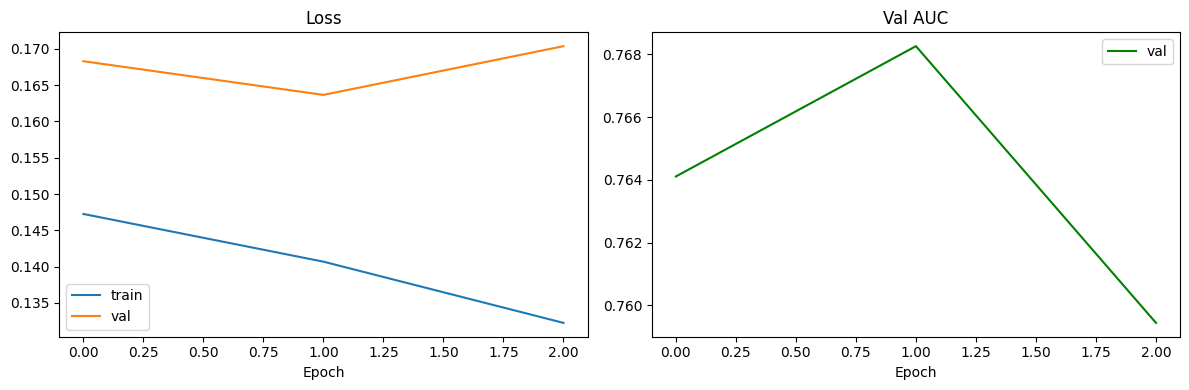

In [16]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history['train_loss'], label='train')
ax1.plot(history['val_loss'],   label='val')
ax1.set_title('Loss'); ax1.legend(); ax1.set_xlabel('Epoch')

ax2.plot(history['val_auc'], label='val', color='green')
ax2.set_title('Val AUC'); ax2.legend(); ax2.set_xlabel('Epoch')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/vit_training_curve.png', dpi=150)
plt.show()

## 11. Değerlendirme — DenseNet ile Aynı Metrikler

In [17]:
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

# En iyi checkpoint'i yükle
model.load_state_dict(torch.load(CHECKPOINT_PATH_VIT))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(DEVICE)
        preds = model(imgs)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(lbls.numpy())

y_pred = np.concatenate(all_preds)
y_true = np.concatenate(all_labels)

print(f"{'Hastalik':22s}  {'En Iyi T':>8}  {'AUC':>6}  {'Sens':>6}  {'Spec':>6}  {'F1':>6}")
print("-" * 66)

aucs = []
best_thresholds = {}

for i, d in enumerate(DISEASE_LABELS):
    try:
        auc = roc_auc_score(y_true[:, i], y_pred[:, i])
    except ValueError:
        auc = float('nan')
    aucs.append(auc)

    # F1 maximize eden eşik — DenseNet notebook ile aynı yöntem
    best_t, best_f1 = 0.5, -1
    for t in np.linspace(0.01, 0.50, 50):
        score = f1_score(y_true[:, i], (y_pred[:, i] >= t).astype(int), zero_division=0)
        if score > best_f1:
            best_f1, best_t = score, t
    best_thresholds[d] = best_t

    yb = (y_pred[:, i] >= best_t).astype(int)
    try:
        tn, fp, fn, tp = confusion_matrix(y_true[:, i], yb, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
        spec = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    except:
        sens = spec = float('nan')

    print(f"{d:22s}  {best_t:8.3f}  {auc:6.3f}  {sens:6.3f}  {spec:6.3f}  {best_f1:6.3f}")

print("-" * 66)
print(f"{'Makro Ortalama':22s}  {'--':>8}  {np.nanmean(aucs):6.3f}")

Hastalik                En Iyi T     AUC    Sens    Spec      F1
------------------------------------------------------------------
Atelectasis                0.140   0.761   0.460   0.859   0.334
Cardiomegaly               0.120   0.850   0.340   0.975   0.311
Effusion                   0.280   0.829   0.569   0.873   0.450
Infiltration               0.210   0.678   0.472   0.786   0.386
Mass                       0.140   0.746   0.277   0.948   0.241
Nodule                     0.080   0.669   0.295   0.900   0.204
Pneumonia                  0.020   0.688   0.181   0.918   0.052
Pneumothorax               0.100   0.831   0.404   0.945   0.319
Consolidation              0.090   0.774   0.390   0.904   0.215
Edema                      0.050   0.859   0.453   0.932   0.199
Emphysema                  0.040   0.833   0.441   0.940   0.231
Fibrosis                   0.040   0.740   0.199   0.954   0.103
Pleural_Thickening         0.100   0.739   0.179   0.966   0.152
Hernia                 

## 12. Attention Map — XAI Görselleştirme

In [19]:
from transformers import ViTModel, ViTConfig
import torch.nn as nn

class ViTChestXray(nn.Module):
    def __init__(self, num_labels=14, dropout=0.3):
        super().__init__()
        # eager modu — output_attentions için zorunlu
        self.vit = ViTModel.from_pretrained(
            'google/vit-base-patch16-224',
            attn_implementation='eager'
        )
        hidden_size = self.vit.config.hidden_size
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, pixel_values):
        outputs    = self.vit(pixel_values=pixel_values)
        cls_output = outputs.last_hidden_state[:, 0, :]
        cls_output = self.dropout(cls_output)
        logits     = self.classifier(cls_output)
        return torch.sigmoid(logits)

    def get_attention_maps(self, pixel_values):
        outputs = self.vit(pixel_values=pixel_values, output_attentions=True)
        return outputs.attentions[-1]

# Modeli yeniden oluştur ve checkpoint'i yükle
model = ViTChestXray(num_labels=len(DISEASE_LABELS)).to(DEVICE)
model.load_state_dict(torch.load(CHECKPOINT_PATH_VIT))
model.eval()
print("Model yüklendi, eager attention aktif ✓")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model yüklendi, eager attention aktif ✓


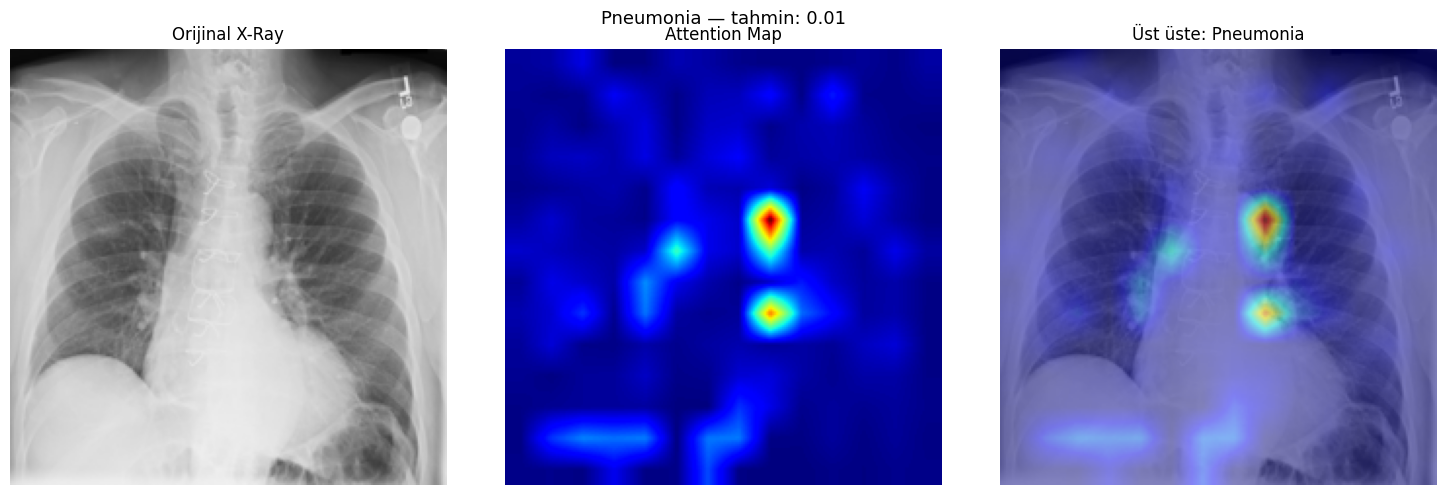

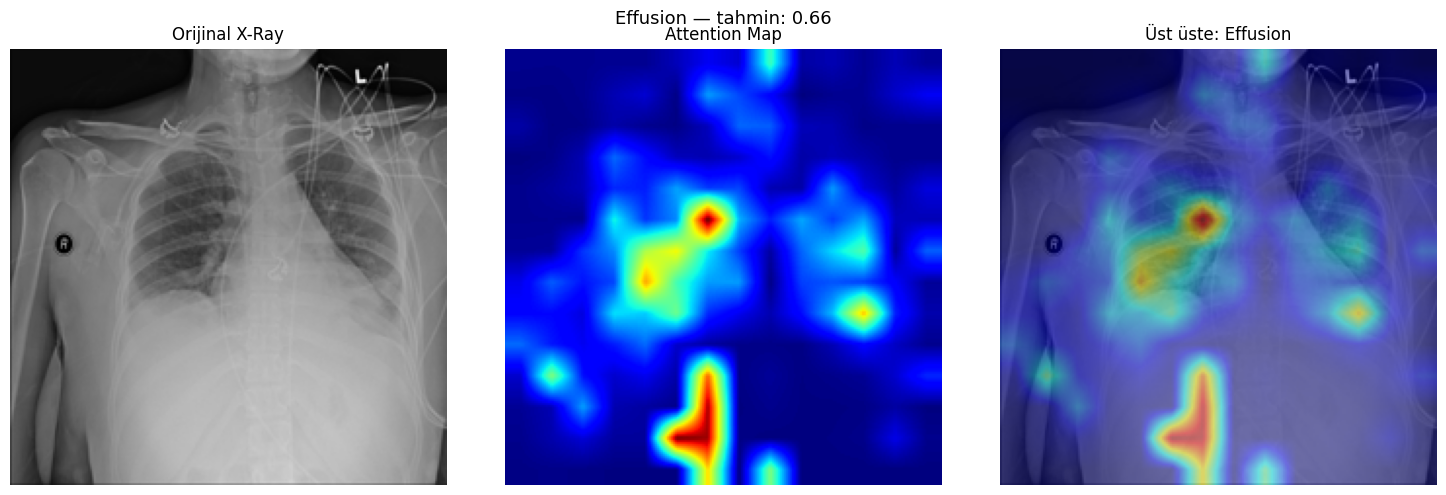

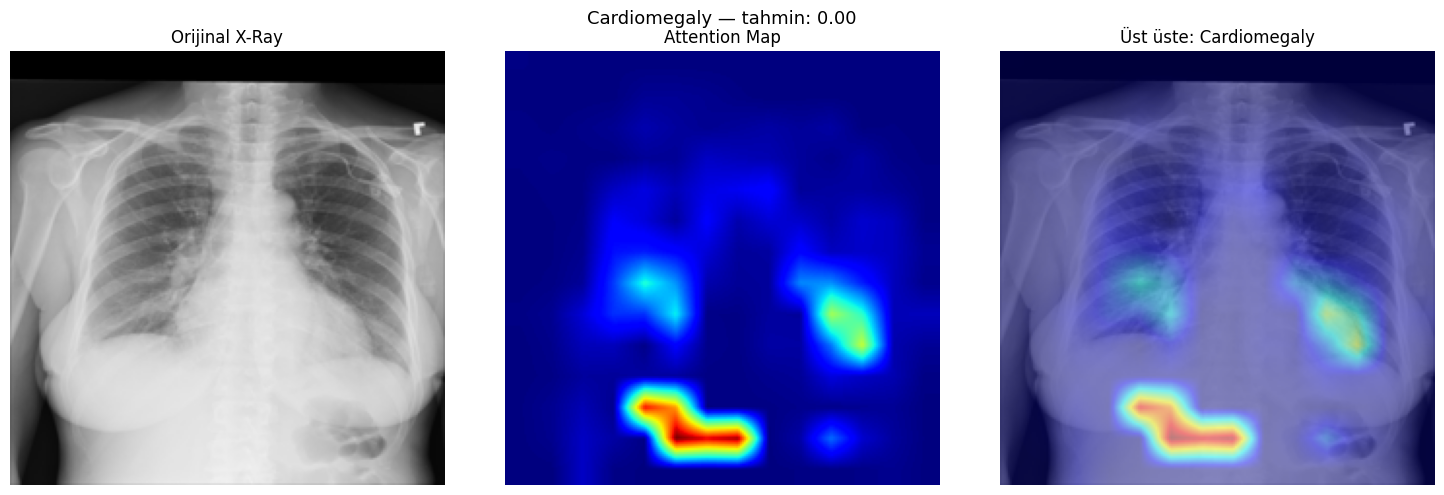

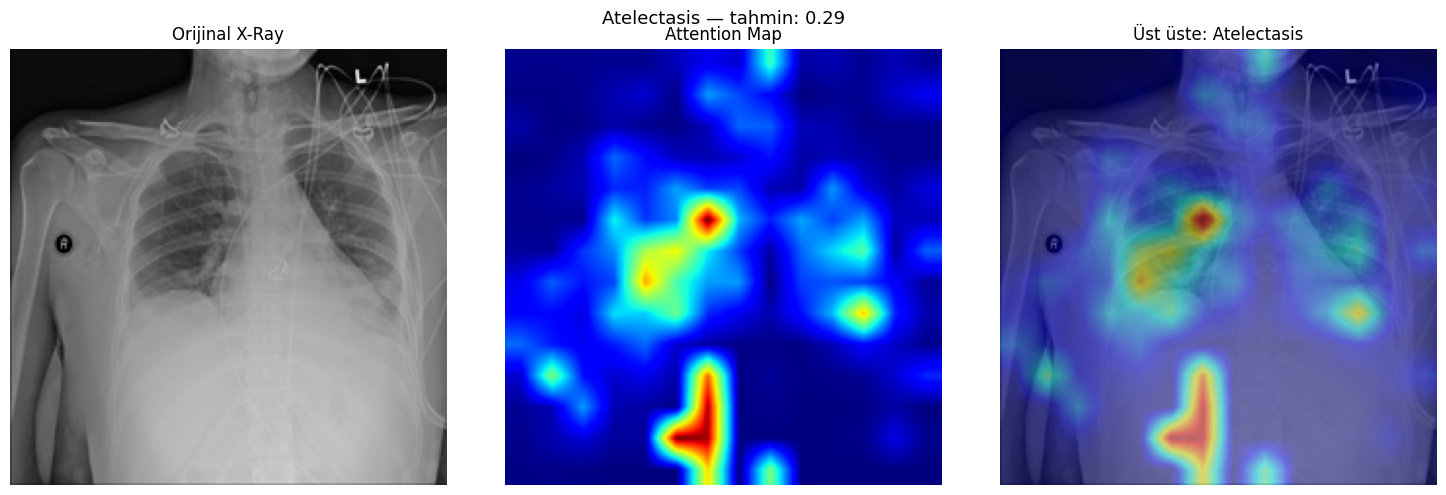

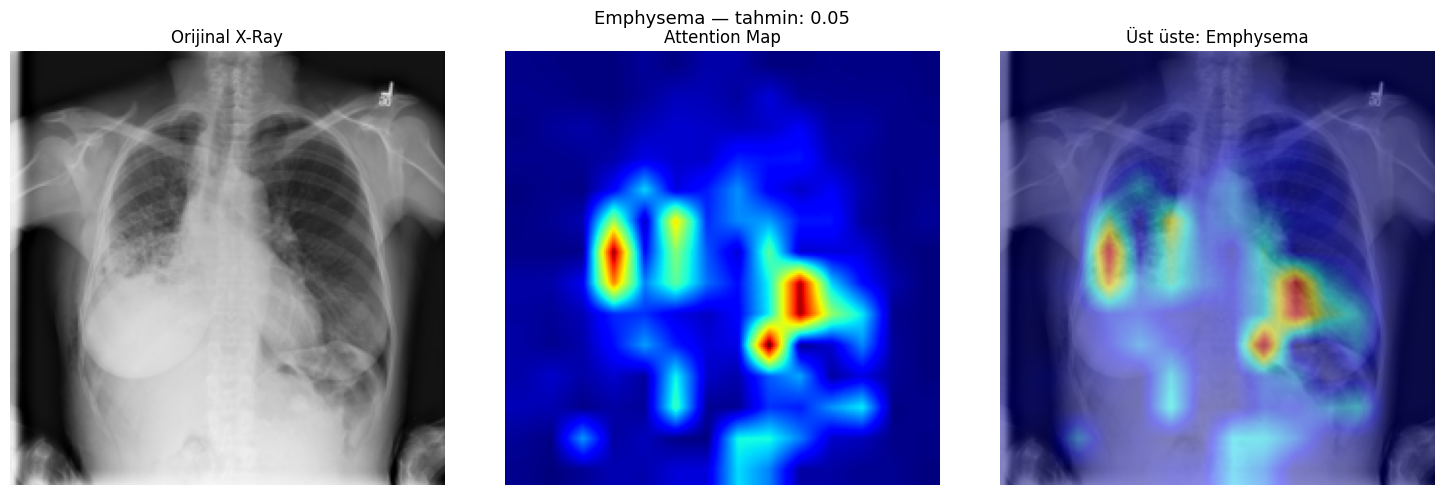

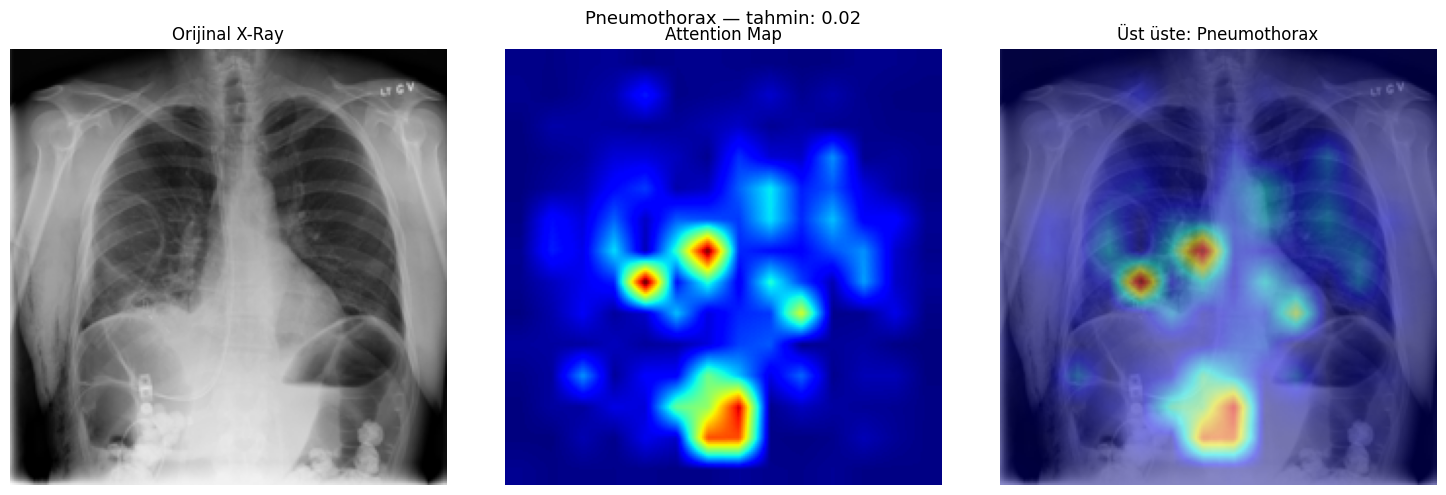

In [21]:
import cv2
from PIL import Image

def show_attention_map(local_path, class_idx, class_name):
    # Görüntüyü yükle
    img_pil = Image.open(local_path).convert('RGB')
    img_tensor = val_transform(img_pil).unsqueeze(0).to(DEVICE)

    model.eval()
    with torch.no_grad():
        pred_score = model(img_tensor)[0][class_idx].item()
    # Attention map al
    attn = model.get_attention_maps(img_tensor)  # (1, heads, seq, seq)
    # [CLS] token'ının diğer patch'lere verdiği attention: ortalama head üzerinden
    attn_cls = attn[0].mean(dim=0)[0, 1:]  # (num_patches,) — ilk token CLS

    # 14x14 grid'e reshape (224/16 = 14)
    grid_size = int(attn_cls.shape[0] ** 0.5)
    attn_map  = attn_cls.reshape(grid_size, grid_size).detach().cpu().numpy()

    # Normalize ve resize
    attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min() + 1e-8)
    attn_resized = cv2.resize(attn_map, (224, 224))
    heatmap = cv2.applyColorMap(np.uint8(255 * attn_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    original     = np.array(img_pil.resize((224, 224)))
    superimposed = cv2.addWeighted(original, 0.55, heatmap, 0.45, 0)

    # Tahmin skoru
    with torch.no_grad():
        pred_score = model(img_tensor)[0][class_idx].item()

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(original);         axes[0].set_title("Orijinal X-Ray");          axes[0].axis('off')
    axes[1].imshow(attn_resized, cmap='jet'); axes[1].set_title("Attention Map");   axes[1].axis('off')
    axes[2].imshow(superimposed);     axes[2].set_title(f"Üst üste: {class_name}"); axes[2].axis('off')
    plt.suptitle(f"{class_name} — tahmin: {pred_score:.2f}", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"/content/drive/MyDrive/attention_{class_name}.png", dpi=150)
    plt.show()

# Her hastalık için bir pozitif örnek göster
for disease in ["Pneumonia", "Effusion", "Cardiomegaly", "Atelectasis", "Emphysema", "Pneumothorax"]:
    pos = test_df[test_df[disease] == 1]
    if len(pos) == 0:
        print(f"{disease}: test kümesinde pozitif örnek yok.")
        continue
    row = pos.iloc[0]
    show_attention_map(row['local_path'], DISEASE_LABELS.index(disease), disease)